In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def load(filepath):
    data = np.genfromtxt(filepath, delimiter= ',', skip_header = 1)
    x = data[:, 1]
    y = data[:, 2]
    return x,y

x_train, y_train = load("lab_1_train.csv")
x_test, y_test = load ("lab_1_test.csv")


print("Length x_train:", len(x_train), "Shape:", x_train.shape)
print("Length y_train:", len(y_train), "Shape:", y_train.shape)

Length x_train: 60 Shape: (60,)
Length y_train: 60 Shape: (60,)


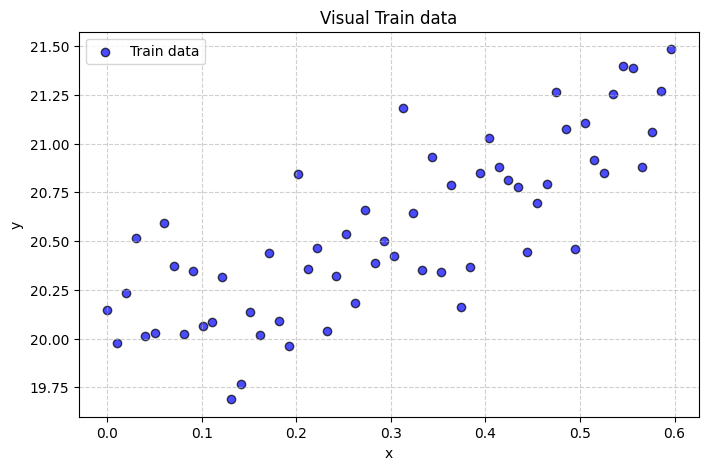

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, color='blue', edgecolors='k', alpha=0.7, label='Train data')
plt.title('Visual Train data')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [4]:
def compute_mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

learning_rate = 0.1
max_epochs = 1000
tolerance = 1e-5
n = len(x_train)

w = 0.0
b = 0.0

prev_loss = float('inf')
converged = False

print("Епоха |     w      |     b      |    MSE Loss    |      Diff")
print("-" * 60)

for epoch in range(1, max_epochs + 1):
    y_pred = w * x_train + b
    loss = compute_mse(y_train, y_pred)
    loss_diff = abs(prev_loss - loss)
    if loss_diff < tolerance:
        print("-" * 60)
        print(f"Збіжність досягнута на епосі {epoch}! Зміна loss ({loss_diff:.2e}) < tolerance ({tolerance:.2e})")
        converged = True
        break
        
    prev_loss = loss
    
    dw = (2 / n) * np.sum((y_pred - y_train) * x_train)
    db = (2 / n) * np.sum(y_pred - y_train)
    
    w -= learning_rate * dw
    b -= learning_rate * db
    
    print(f"{epoch:5d} | {w:10.6f} | {b:10.6f} | {loss:14.6f} | {loss_diff:12.2e}")

if not converged:
    print(f"Досягнуто ліміт епох ({max_epochs}) без повної збіжності за tolerance.")

print(f"\nФінальне рівняння прямої: y = {w:.4f}x + {b:.4f}")

Епоха |     w      |     b      |    MSE Loss    |      Diff
------------------------------------------------------------
    1 |   1.236781 |   4.109913 |     422.477402 |          inf
    2 |   2.199096 |   7.324136 |     258.370610 |     1.64e+02
    3 |   2.946877 |   9.838164 |     158.082976 |     1.00e+02
    4 |   3.526977 |  11.804822 |      96.795295 |     6.13e+01
    5 |   3.976019 |  13.343576 |      59.340534 |     3.75e+01
    6 |   4.322636 |  14.547819 |      36.450108 |     2.29e+01
    7 |   4.589208 |  15.490556 |      22.459978 |     1.40e+01
    8 |   4.793231 |  16.228859 |      13.908845 |     8.55e+00
    9 |   4.948383 |  16.807343 |       8.681506 |     5.23e+00
   10 |   5.065355 |  17.260883 |       5.485360 |     3.20e+00
   11 |   5.152504 |  17.616745 |       3.530496 |     1.95e+00
   12 |   5.216364 |  17.896240 |       2.334200 |     1.20e+00
   13 |   5.262043 |  18.116030 |       1.601484 |     7.33e-01
   14 |   5.293532 |  18.289140 |       1.1520

In [5]:
y_test_pred = w * x_test + b

test_mse = compute_mse(y_test, y_test_pred)
print(f"MSE на тестовому датасеті: {test_mse:.6f}")

MSE на тестовому датасеті: 0.075319


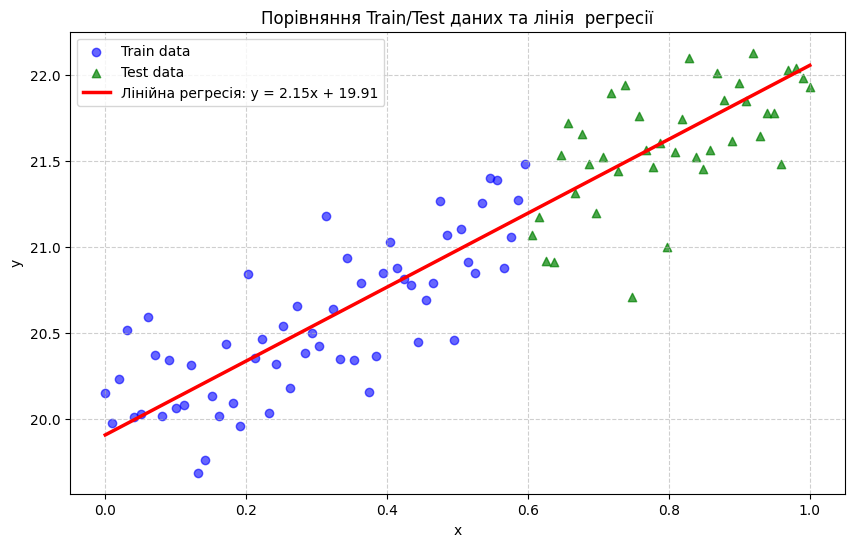

In [6]:
plt.figure(figsize=(10, 6))

plt.scatter(x_train, y_train, color='blue', alpha=0.6, label='Train data')
plt.scatter(x_test, y_test, color='green', marker='^', alpha=0.7, label='Test data')

x_line = np.linspace(min(np.min(x_train), np.min(x_test)), 
                     max(np.max(x_train), np.max(x_test)), 100)
y_line = w * x_line + b

plt.plot(x_line, y_line, color='red', linewidth=2.5, label=f'Лінійна регресія: y = {w:.2f}x + {b:.2f}')

plt.title('Порівняння Train/Test даних та лінія  регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()